# Pretraining the GPT (the training loop)

This notebook fills the `04` slot in the build path: the step where the `GPTModel` we
assembled in [`03_transformer_block.ipynb`](03_transformer_block.ipynb) actually *learns*
by training on text, before we adapt it in
[`06_finetuning_classification.ipynb`](06_finetuning_classification.ipynb).

Where this sits in the lifecycle:

```
01 data prep  ->  02 attention  ->  03 transformer block / GPTModel
                                          |
                                   >> 04 PRETRAINING <<   (this notebook)
                                          |
                          05 decoding  ->  06 finetuning (classification)
```

Roughly follows Sebastian Raschka's *Build a Large Language Model (From Scratch)*, ch. 5.

## What this notebook covers

- **Cross-entropy loss for language modeling**: comparing the model's next-token
  logits against the shifted target tokens (the `(input, target)` pairs built in
  [`01_data_prep.ipynb`](01_data_prep.ipynb)).
- **Train / validation loss helpers**: `calc_loss_batch` and `calc_loss_loader`.
- **The training loop**: `AdamW`, gradient steps, periodic evaluation, and tracking
  train vs. validation loss over time.
- **Sampling during training**: generating a short completion every epoch to
  *watch* the model improve (reuses `generate_text` from
  [`utils/text_generator.py`](utils/text_generator.py)).
- **Saving / loading weights**: `torch.save` / `torch.load` of the model and
  optimizer state.

The decoding strategies used while sampling (temperature, top-k) are explored on
their own in [`05_decoding.ipynb`](05_decoding.ipynb).

In [1]:
# Reuse the model + generation helpers we already built.
# (Run with llms/ as the working directory so `from utils import ...` resolves.)
import os
import urllib.request

import matplotlib.pyplot as plt
import tiktoken
import torch
from torch.utils.data import DataLoader, Dataset

from utils import GPTModel
from utils import generate_text, text_to_token_ids, token_ids_to_text

torch.manual_seed(123)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

Device: mps


## 1. Model configuration

Same GPT-2 small architecture as in `03`, but with a shorter context (256 instead of
1024 tokens) so it trains in under a minute on a laptop GPU. Our `GPTModel` does not tie
the input embedding and output head weights, so it has ~162M parameters rather than
GPT-2's 124M.

In [2]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # GPT-2 BPE vocabulary (tiktoken "gpt2")
    "context_length": 256,   # shortened from 1024 to keep training cheap
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False,
}

tokenizer = tiktoken.get_encoding("gpt2")

## 2. Data: text -> token ids -> (input, target) batches

We reuse the sliding-window dataset from [`01_data_prep.ipynb`](01_data_prep.ipynb):
each target sequence is the input shifted one token to the right. The corpus is the
short story *The Verdict* (~5k tokens), which is tiny, so expect the model to memorize
it. That is fine here: the goal is to see the training mechanics work end to end.

In [3]:
file_path = "../data/TheVerdict/the-verdict.txt"
if not os.path.exists(file_path):
    os.makedirs(os.path.dirname(file_path), exist_ok=True)
    url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"
    urllib.request.urlretrieve(url, file_path)

with open(file_path, "r", encoding="utf-8") as f:
    text_data = f.read()

print("Characters:", len(text_data))
print("Tokens:", len(tokenizer.encode(text_data)))

Characters: 20479
Tokens: 5145


In [4]:
class GPTDataset(Dataset):
    """Sliding-window next-token dataset (same as in 01_data_prep)."""

    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids, self.target_ids = [], []
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})
        for i in range(0, len(token_ids) - max_length, stride):
            self.input_ids.append(torch.tensor(token_ids[i:i + max_length]))
            self.target_ids.append(torch.tensor(token_ids[i + 1:i + max_length + 1]))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


def create_dataloader(txt, batch_size, max_length, stride, shuffle, drop_last):
    dataset = GPTDataset(txt, tokenizer, max_length, stride)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last)


# 90/10 train/validation split on the raw text
split_idx = int(0.9 * len(text_data))
ctx = GPT_CONFIG_124M["context_length"]

torch.manual_seed(123)
train_loader = create_dataloader(text_data[:split_idx], batch_size=2, max_length=ctx,
                                 stride=ctx, shuffle=True, drop_last=True)
val_loader = create_dataloader(text_data[split_idx:], batch_size=2, max_length=ctx,
                               stride=ctx, shuffle=False, drop_last=False)

x, y = next(iter(train_loader))
print("Train batches:", len(train_loader), "| Val batches:", len(val_loader))
print("Input batch:", x.shape, "| Target batch:", y.shape)

Train batches: 9 | Val batches: 1
Input batch: torch.Size([2, 256]) | Target batch: torch.Size([2, 256])


## 3. Cross-entropy loss for language modeling

The model outputs logits of shape `(batch, tokens, vocab)`. For next-token prediction we
flatten batch and token dimensions and compare against the target ids with
cross-entropy. An untrained model is roughly uniform over the vocabulary, so its loss
should start near `ln(50257) ≈ 10.8`.

In [5]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)                              # (B, T, V)
    return torch.nn.functional.cross_entropy(
        logits.flatten(0, 1), target_batch.flatten()         # (B*T, V) vs (B*T,)
    )


def calc_loss_loader(data_loader, model, device, num_batches=None):
    if len(data_loader) == 0:
        return float("nan")
    num_batches = len(data_loader) if num_batches is None else min(num_batches, len(data_loader))
    total = 0.0
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i >= num_batches:
            break
        total += calc_loss_batch(input_batch, target_batch, model, device).item()
    return total / num_batches

In [6]:
import math

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M).to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

with torch.no_grad():
    print("Initial train loss:", round(calc_loss_loader(train_loader, model, device), 3))
    print("Initial val loss:  ", round(calc_loss_loader(val_loader, model, device), 3))
print("ln(vocab_size):    ", round(math.log(GPT_CONFIG_124M["vocab_size"]), 3))

Parameters: 162,419,712


Initial train loss: 10.985
Initial val loss:   10.993
ln(vocab_size):     10.825


## 4. The training loop

Per step: zero gradients -> forward + loss -> backward -> `AdamW` update. Every
`eval_freq` steps we switch to `eval()` mode (dropout off) and estimate train and
validation loss; after each epoch we print a greedy sample from a fixed prompt.

In [7]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss


def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    token_ids = generate_text(model, encoded, max_new_tokens=50, context_size=context_size)
    print(token_ids_to_text(token_ids, tokenizer).replace("\n", " "))
    model.train()


def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    train_losses, val_losses, tokens_seen_track = [], [], []
    tokens_seen, global_step = 0, -1

    for epoch in range(num_epochs):
        model.train()
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward()
            optimizer.step()
            tokens_seen += input_batch.numel()
            global_step += 1

            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                tokens_seen_track.append(tokens_seen)
                print(f"Ep {epoch + 1} (step {global_step:03d}): "
                      f"train loss {train_loss:.3f}, val loss {val_loss:.3f}")

        generate_and_print_sample(model, tokenizer, device, start_context)

    return train_losses, val_losses, tokens_seen_track

In [8]:
import time

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=4e-4, weight_decay=0.1)

num_epochs = 10
start = time.time()
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer,
)
print(f"Training took {(time.time() - start) / 60:.2f} min")

Ep 1 (step 000): train loss 9.817, val loss 9.924


Ep 1 (step 005): train loss 8.067, val loss 8.333


Every effort moves you,,,,,,,,,,,,.                                     


Ep 2 (step 010): train loss 6.620, val loss 7.045


Ep 2 (step 015): train loss 6.040, val loss 6.597


Every effort moves you, and,, and, and, and,,, and,.                                   


... (17 outputs left out)

Ep 9 (step 080): train loss 0.634, val loss 6.372


Every effort moves you?"  "Yes--quite insensible to the irony. She wanted him vindicated--and by me!"  He laughed again, and threw back his head to look up at the sketch of the donkey. "There were days when I


Ep 10 (step 085): train loss 0.447, val loss 6.474


Every effort moves you?"  "Yes--quite insensible to the irony. She wanted him vindicated--and by me!"  He laughed again, and threw back his head to look up at the sketch of the donkey. "There were days when I
Training took 0.30 min


## 5. Train vs. validation loss

Training loss keeps falling while validation loss flattens and then rises: with only
~5k tokens the model overfits (memorizes the story). The samples above show the same
thing: they become fluent but increasingly copy passages from the training text. More
data, not more epochs, is the fix, which is exactly why pretraining corpora are huge.

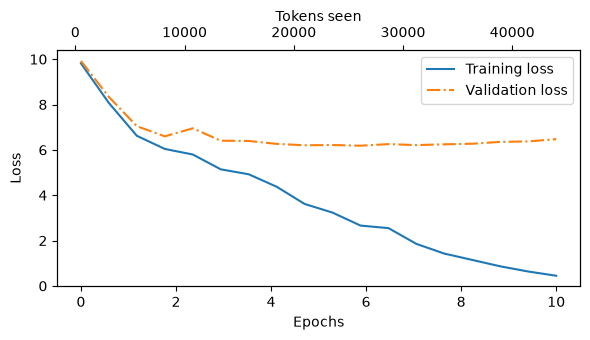

Best val loss: 6.184 | final train loss: 0.447


In [9]:
epochs_seen = torch.linspace(0, num_epochs, len(train_losses))

fig, ax1 = plt.subplots(figsize=(6, 3.5))
ax1.plot(epochs_seen, train_losses, label="Training loss")
ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
ax1.legend(loc="upper right")

ax2 = ax1.twiny()  # second x-axis: tokens seen
ax2.plot(tokens_seen, train_losses, alpha=0)
ax2.set_xlabel("Tokens seen")

fig.tight_layout()
plt.show()

print(f"Best val loss: {min(val_losses):.3f} | final train loss: {train_losses[-1]:.3f}")

## 6. Sampling from the trained model

Greedy decoding replays memorized text; temperature and top-k sampling (see
[`05_decoding.ipynb`](05_decoding.ipynb)) trade that for more varied output.

In [10]:
model.eval()
prompt = text_to_token_ids("Every effort moves you", tokenizer).to(device)
ctx = GPT_CONFIG_124M["context_length"]

torch.manual_seed(123)
greedy = generate_text(model, prompt, max_new_tokens=25, context_size=ctx)
sampled = generate_text(model, prompt, max_new_tokens=25, context_size=ctx,
                        temperature=1.4, top_k=25)
print("Greedy:          ", token_ids_to_text(greedy, tokenizer))
print("Temp 1.4, top-25:", token_ids_to_text(sampled, tokenizer))

Greedy:           Every effort moves you?"

"Yes--quite insensible to the irony. She wanted him vindicated--and by me!"


Temp 1.4, top-25: Every effort moves you like him, and in the Mrs. Gisburn--as such--had not existed till nearly aoust went on grop


## 7. Saving and loading weights

Save both the model and the optimizer state: AdamW keeps per-parameter moment
estimates, so resuming training without them restarts the optimizer from scratch.
Checkpoints go under `assets/`, which is git-ignored (~2 GB with optimizer state).

In [11]:
os.makedirs("assets", exist_ok=True)
ckpt_path = "assets/gpt_pretrained_verdict.pth"
torch.save({"model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict()}, ckpt_path)

checkpoint = torch.load(ckpt_path, map_location=device)
restored = GPTModel(GPT_CONFIG_124M).to(device)
restored.load_state_dict(checkpoint["model_state_dict"])
restored_opt = torch.optim.AdamW(restored.parameters(), lr=4e-4, weight_decay=0.1)
restored_opt.load_state_dict(checkpoint["optimizer_state_dict"])
restored.eval()

with torch.no_grad():
    print("Restored val loss:", round(calc_loss_loader(val_loader, restored, device), 3))

Restored val loss: 6.486
